# 02 — Exploratory Data Analysis

Explore feature distributions and relationships. Keep the target in mind, but the leakage-safe modelling split happens later (notebook 03).

In [1]:
import sys
from pathlib import Path

# Make the project root importable (so `import src...` works).
ROOT = Path.cwd()
if (ROOT / 'src').exists() is False and (ROOT.parent / 'src').exists():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))

import pandas as pd
import matplotlib.pyplot as plt

from src.utils import config
config.ensure_directories()

In [2]:
from src.data import load_data, preprocessing
from src.analysis import eda
from src.visualization import plots

df = load_data.load_dataset()
X, y = preprocessing.separate_features_target(df)
num_cols = preprocessing.identify_numerical_features(X)
cat_cols = preprocessing.identify_categorical_features(X)
print(f'{len(num_cols)} numeric, {len(cat_cols)} categorical features')

44 numeric, 7 categorical features


## Numerical summaries

In [3]:
eda.numerical_summary(df, num_cols)

,count,mean,std,min,25%,50%,75%,max
age,10000.0,20.652400,2.183404,17.00,19.00,20.00,22.0000,28.0
semester,10000.0,4.983700,1.936339,2.00,3.00,5.00,7.0000,8.0
admission_score,10000.0,62.331600,16.719886,20.00,50.90,62.40,73.7000,99.0
previous_semester_gpa,10000.0,2.498058,0.695779,0.45,2.02,2.50,2.9800,4.0
previous_semester_credits_attempted,10000.0,21.003300,2.179808,16.00,20.00,21.00,22.0000,28.0
previous_semester_credits_completed,10000.0,18.495900,3.722764,0.00,16.00,19.00,21.0000,28.0
previous_semester_attendance_percentage,10000.0,68.700050,14.411455,25.00,59.10,69.10,78.6000,100.0
backlogs_previous_semester,10000.0,0.527900,0.802300,0.00,0.00,0.00,1.0000,5.0
previous_semester_failed_subjects,10000.0,0.793500,0.858680,0.00,0.00,1.00,1.0000,6.0
internal_assessment_score,10000.0,60.029530,14.808355,5.00,49.90,60.20,70.2000,100.0


## Categorical value counts

In [4]:
summaries = eda.categorical_summary(df, cat_cols)
for col, counts in summaries.items():
    print(col)
    print(counts, '\n')

gender
gender
Male      5183
Female    4505
Other      312
Name: count, dtype: int64 

program
program
BTech    3053
BCA      2030
BSc      1712
MCA      1680
MSc      1525
Name: count, dtype: int64 

department
department
Mechanical                2065
Civil                     2036
Computer Science          2012
Electronics               1963
Information Technology    1924
Name: count, dtype: int64 

scholarship_status
scholarship_status
No     5597
Yes    4403
Name: count, dtype: int64 

residence_type
residence_type
Urban     4455
Rural     3088
Hostel    2457
Name: count, dtype: int64 

attendance_trend
attendance_trend
Declining    3719
Improving    3387
Stable       2894
Name: count, dtype: int64 

extracurricular_participation
extracurricular_participation
No     5483
Yes    4517
Name: count, dtype: int64 



## Correlation analysis

In [5]:
eda.top_correlations(df, threshold=0.7)

,feature_a,feature_b,abs_correlation
0,classes_attended,attendance_percentage,0.921
1,quiz_attempts,quiz_completion_rate,0.879
2,subjects_enrolled,credits_enrolled,0.877
3,subjects_enrolled,assignments_assigned,0.835
4,assignments_submitted,assignment_submission_rate,0.788
5,forum_posts,discussion_participation_score,0.764
6,forum_replies,discussion_participation_score,0.748
7,credits_enrolled,assignments_assigned,0.734
8,previous_semester_credits_completed,backlogs_previous_semester,0.730


## Target distribution plot

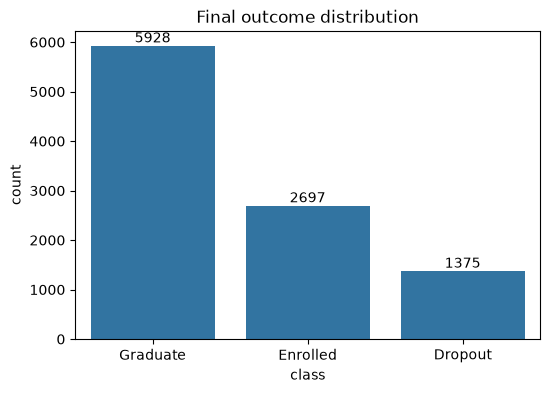

In [6]:
plots.plot_class_distribution(y, title='Final outcome distribution',
                              save_path='eda_class_distribution.png')
plt.show()